Dataset: /ihome/cmpinf0010-sec1010_2026f/rug85/Final-Project/Rushil_Dataset.csv
Original records: 3,594
Relevant records: 3,594
Records missing a neighborhood: 0
Records missing a parcel ID: 0
Repeated parcel records removed: 677
Unique properties counted: 2,917

Full ranking (lower counts are better):
 rank              neighborhood  property_count  rank_score
    1            Allegheny West               1    0.021277
    1         Arlington Heights               1    0.021277
    1 Central Business District               1    0.021277
    1           Central Oakland               1    0.021277
    1                Friendship               1    0.021277
    1               North Shore               1    0.021277
    1       Squirrel Hill North               1    0.021277
    1            Swisshelm Park               1    0.021277
    2                Banksville               2    0.042553
    2             North Oakland               2    0.042553
    2            Strip District     

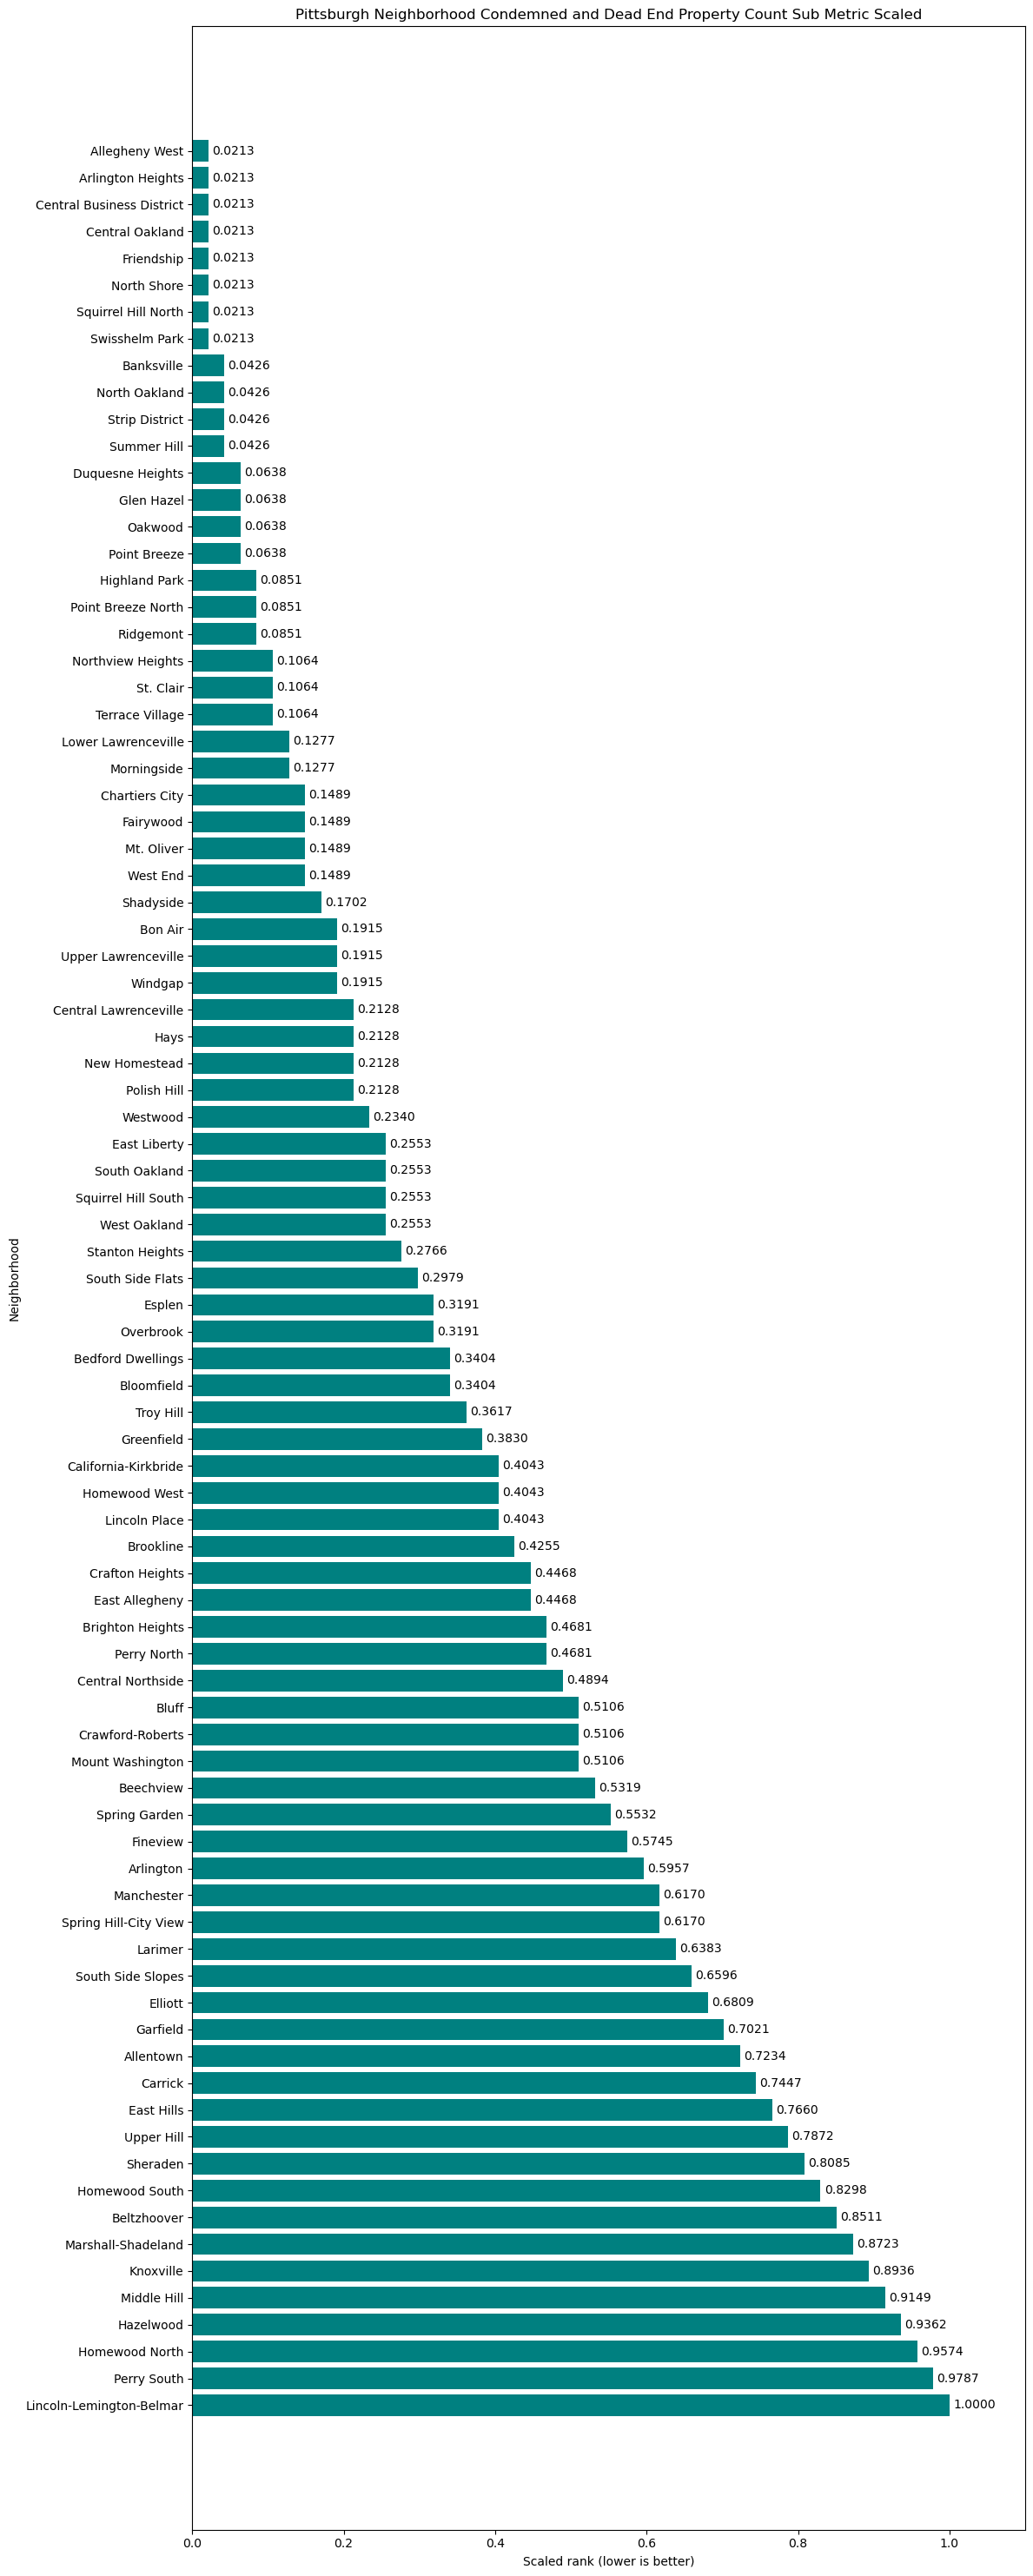


Best neighborhood(s) under this submetric: Allegheny West, Arlington Heights, Central Business District, Central Oakland, Friendship, North Shore, Squirrel Hill North, Swisshelm Park
Each has 1 unique condemned/dead-end property parcel(s).

I defined bestness as having the fewest recorded condemned/dead-end properties. I counted unique parcel IDs instead of inspection records so repeated inspections would not inflate the totals. The result above identifies the winner or tied winners among neighborhoods in this file.

Limitations: This is a raw count, so larger neighborhoods may have more properties simply because they are larger. It is not a rate or a complete measure of neighborhood quality. Neighborhoods absent from this file cannot automatically be assigned zero; a complete neighborhood list and confirmation of coverage would be needed. This file also does not establish coverage of locations outside Pittsburgh. Results describe this CSV snapshot.

Saved: condemned_properties_neighb

In [4]:
# %% Introduction
# Individual submetric: fewest condemned/dead-end properties.
# Lower counts are better. This analysis includes every neighborhood recorded
# in the supplied dataset; it does not apply an additional Pittsburgh filter.
# The dataset combines condemned and dead-end properties in one category.

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# %% Load the dataset
# Use the script folder when running this file, or the working folder in Jupyter.
BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_PATH = BASE_DIR / "Rushil_Dataset.csv"

# Read IDs as text to preserve leading zeros.
df = pd.read_csv(DATA_PATH, dtype="string")
required = {"parcel_id", "neighborhood", "property_type"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

for column in required:
    df[column] = df[column].str.strip().replace("", pd.NA)

print(f"Dataset: {DATA_PATH}")
print(f"Original records: {len(df):,}")

# %% Clean the data
# Select the relevant property category. Do not count inspection rows as
# separate properties: a parcel can appear more than once in this dataset.
properties = df.loc[
    df["property_type"].str.contains(
        r"condemned|dead[\s-]*end", case=False, na=False
    )
].copy()

missing_location = properties["neighborhood"].isna().sum()
missing_id = properties["parcel_id"].isna().sum()
print(f"Relevant records: {len(properties):,}")
print(f"Records missing a neighborhood: {missing_location:,}")
print(f"Records missing a parcel ID: {missing_id:,}")
properties = properties.dropna(subset=["neighborhood", "parcel_id"])

# Stop if a parcel has conflicting neighborhood labels, since silently picking
# one would change the results. Inspect and correct those labels before rerunning.
locations_per_parcel = properties.groupby("parcel_id")["neighborhood"].nunique()
conflicts = locations_per_parcel[locations_per_parcel > 1]
if not conflicts.empty:
    print(properties.loc[properties["parcel_id"].isin(conflicts.index),
                         ["parcel_id", "neighborhood"]].drop_duplicates())
    raise ValueError("Some parcels have conflicting neighborhoods. Resolve these before ranking.")

unique_properties = properties.drop_duplicates(subset="parcel_id")
print(f"Repeated parcel records removed: {len(properties) - len(unique_properties):,}")
print(f"Unique properties counted: {len(unique_properties):,}")
if unique_properties.empty:
    raise ValueError("No properties remain for analysis.")

# %% The metric and ranking
# Metric = number of unique condemned/dead-end parcels in each neighborhood.
# Ties share a rank and the next distinct count receives the next integer.
ranking = (
    unique_properties.groupby("neighborhood")["parcel_id"]
    .nunique()
    .rename("property_count")
    .reset_index()
    .sort_values(["property_count", "neighborhood"])
    .reset_index(drop=True)
)
ranking["rank"] = ranking["property_count"].rank(method="dense").astype(int)
total_ranks = ranking["rank"].nunique()
ranking["rank_score"] = ranking["rank"] / total_ranks
ranking = ranking[["rank", "neighborhood", "property_count", "rank_score"]]
print("\nFull ranking (lower counts are better):")
print(ranking.to_string(index=False))

# Include every neighborhood.

# %% Visualization
fig, ax = plt.subplots(figsize=(12, max(5, len(ranking) * 0.35)))

bars = ax.barh(ranking["neighborhood"], ranking["rank_score"], color="teal")
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.4f", padding=3)

ax.set_title(
    "Pittsburgh Neighborhood Condemned and Dead End Property Count Sub Metric Scaled"
)
ax.set_xlabel("Scaled rank (lower is better)")
ax.set_ylabel("Neighborhood")
ax.set_xlim(0, 1.10)

fig.tight_layout()
plt.show()

# %% Results and conclusion
minimum = int(ranking["property_count"].min())
winners = ranking.loc[ranking["property_count"] == minimum, "neighborhood"].tolist()
print("\nBest neighborhood(s) under this submetric:", ", ".join(winners))
print(f"Each has {minimum} unique condemned/dead-end property parcel(s).")
print(
    "\nI defined bestness as having the fewest recorded condemned/dead-end "
    "properties. I counted unique parcel IDs instead of inspection records "
    "so repeated inspections would not inflate the totals. The result above "
    "identifies the winner or tied winners among neighborhoods in this file."
)
print(
    "\nLimitations: This is a raw count, so larger neighborhoods may have more "
    "properties simply because they are larger. It is not a rate or a complete "
    "measure of neighborhood quality. Neighborhoods absent from this file "
    "cannot automatically be assigned zero; a complete neighborhood list and "
    "confirmation of coverage would be needed. This file also does not establish "
    "coverage of locations outside Pittsburgh. Results describe this CSV snapshot."
)
# My personal favourite neighborhood is Allegheny West and the data too supports it as the lowest no of condemned properties are found there.

# %% Save results for the group's combined analysis
ranking.to_csv("condemned_properties_neighborhood_ranking.csv", index=False)
print("\nSaved: condemned_properties_neighborhood_ranking.csv")

